# Part A — Guided Filtering preprocessing pipeline

An edge-preserving smoothing pipeline for cervical colposcopy images. This
notebook is a full rewrite of the previous **QI-SABP** (quantum-inspired
saliency + bit-allocation) preprocessing notebook.

## QI-SABP removal statement

Every QI-SABP technique and every QI-SABP configuration item has been
removed. Nothing from the QI-SABP pipeline remains in this notebook:

* fused saliency map (Sobel + FFT spectral residual + multi-scale contrast +
  local entropy) and all of its weights / normalisation modes,
* glare mask, whiteness channel, FOV-rim erode/margin rules,
* soft mask (gain / threshold / coverage), hard-mask hole filling,
* rim/size rule and minimum-area component filter,
* continuous bit allocation (salient/non-salient Y/C bits, edge boost),
* adaptive dithered quantisation, YCbCr 4:2:0 chroma subsampling,
* NLM pre-denoise, bilateral post-filter, partial histogram matching.

The "quantum-inspired" framing, the soft-mask / bit-map artefacts and the
corresponding ablation variants are gone with them.

## What is Guided Filtering here

The guided filter (He, Sun & Tang; ECCV 2010, TPAMI 2013) is a native
edge-preserving smoothing operator. It assumes a **local linear model**
between the guidance image `I` and the filter output `q` inside a square
window `w_k` of radius `r` centred at pixel `k`:

    q_i = a_k * I_i + b_i        for all i in w_k

Because `q` follows the gradients of `I`, the output keeps the edges of the
guidance image instead of blurring across them. The coefficients have a
closed-form least-squares solution,

    a_k = cov(I, p) / (var(I) + eps)
    b_k = mean(p) - a_k * mean(I)

where `p` is the image being filtered, and the final output is the
windowed average of the per-window coefficients,

    q_i = mean(a) * I_i + mean(b).

Two knobs control the behaviour:

* `radius r` — window size; larger means broader flattening,
* `eps` — variance floor; small `eps` = strong edge preservation (near
  pass-through at edges), large `eps` = heavier smoothing.

Every window operation is a **box filter** (local mean), computable in O(N)
with running sums, so the filter is exact — not an approximation — and fast
at any radius. This notebook ships a self-contained box-filter
implementation built on `cv2.boxFilter`, so no `opencv-contrib` dependency
is required.

The pipeline is **self-guided on the luma channel only**: the image is
converted to YCbCr, the guided filter is applied to `Y` with `I = p = Y`,
and `Cb` / `Cr` are copied through unchanged. Chroma is therefore never
touched by the filter, so the colour metrics in Part B (a* correlation,
ΔE76) are driven purely by the luma change.

## Pipeline overview

* Step 1 — Unsharp-mask sharpen, carried over from Step 1 unchanged
  (amount 0.8, ksize 5).
* Step 2 — Guided filter: self-guided luma smoothing, radius 8, eps 1e-3
  (eps on the normalised 0-1 intensity scale, the reference
  implementation's convention).

## Output

The pipeline returns a **uint8 RGB image, same shape as the input**. It is
NOT a compression scheme and it is NOT lossless: the guided filter is a
smoothing operator, and every metric in Part B is computed against the
ORIGINAL image to quantify exactly what the smoothing changed.

## What this notebook does NOT claim

* It does NOT produce a compressed byte stream.
* It does NOT benchmark techniques against each other (the Identity row in
  Part B is a reference for sanity, not a competing technique).
* It does NOT demonstrate a clinical benefit on this single patient.
* "Luma bits" is no longer a bit-allocation quantity (QI-SABP is gone). It
  is now the first-order Shannon entropy of the luma histogram inside the
  FOV — the bits/px a memoryless coder would need for the luma channel.


In [1]:
# ============================================================
# Cell 1.1 -- Combined imports & global setup
# ============================================================
import os, glob, time, json, math, random, warnings, platform

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt

import pandas as pd
from scipy import ndimage
from scipy.ndimage import gaussian_filter

warnings.filterwarnings('ignore')

# Reproducibility. The guided filter itself is fully deterministic; the
# seed governs the synthetic fallback dataset only.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Output directory for results / CSV artefacts
# Relative path so the notebook is portable across Windows / Linux / macOS.
SAVE_DIR = 'results'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"\nGuided Filtering Validation Pipeline — Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__}")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")



Guided Filtering Validation Pipeline — Python 3.10.20
NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0
Random seed: 42
Output directory: results
All imports OK.


In [2]:
# ============================================================
# Cell 1.2 -- Configuration
#   Single-class invasive carcinoma dataset.
#   Expected layout (configurable below):
#       <DATASET_ROOT>/<INVASIVE_DIR>/images/*.jpg
#       <DATASET_ROOT>/<INVASIVE_DIR>/<MASKS_SUBDIR>/*.png
#
#   All QI-SABP configuration (saliency weights, glare / rim / soft-mask
#   rules, bit budgets, dither, NLM, bilateral, histogram match) has been
#   REMOVED. The only preprocessing knobs left are the Step-1 sharpen and
#   the guided-filter parameters below.
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Data ----
# Use forward slashes -- works on both Windows and Linux/macOS.
DATASET_ROOT   = "C:/CER/dataset"   # <-- your dataset root
INVASIVE_DIR   = "invasive cancer"  # <-- single class folder (note the space)
MASKS_SUBDIR   = "masks"            # set "" if masks live directly under invasive cancer/
CLASSES        = ["invasive cancer"]  # only one class

# ---- Sharpen (Step 1, carried over unchanged) ----
APPLY_SHARPEN  = True
SHARPEN_AMOUNT = 0.8
SHARPEN_KSIZE  = 5

# ---- Guided filter (Step 2) ----
# radius : window radius r of the local linear model (px). Larger = flatter.
# eps    : variance floor on the NORMALISED 0-1 intensity scale (the
#          reference implementation's convention; pixels are divided by
#          255 internally). Small = strong edge preservation.
# mode   : "luma" = filter the Y channel of YCbCr only (Cb/Cr untouched);
#          "rgb"  = filter each RGB channel with the grayscale image as
#          guidance. The validated configuration is "luma".
GF_RADIUS = 8
GF_EPS    = 1e-3
GF_MODE   = "luma"

# Global flag set later by the loader -- declared here so all downstream
# cells can reference it without NameError.
SYNTHETIC_MODE = False

# ---- Validation batch (Part B) ----
# All loaded frames are validated (SUBSET_PER_CLASS=None keeps every frame).
SUBSET_PER_CLASS = None

print(f"Configuration OK  |  classes={CLASSES}  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  sharpen={APPLY_SHARPEN} (amount={SHARPEN_AMOUNT}, ksize={SHARPEN_KSIZE})")
print(f"  guided filter: radius={GF_RADIUS}, eps={GF_EPS}, mode={GF_MODE} "
      f"(self-guided; chroma untouched in luma mode)")
print(f"  validation batch = all loaded frames (SUBSET_PER_CLASS={SUBSET_PER_CLASS})")


Configuration OK  |  classes=['invasive cancer']  |  img=200x200
  sharpen=True (amount=0.8, ksize=5)
  guided filter: radius=8, eps=0.001, mode=luma (self-guided; chroma untouched in luma mode)
  validation batch = all loaded frames (SUBSET_PER_CLASS=None)


In [3]:
# ============================================================
# Cell 1.3 -- Sharpen + preprocess + load_dataset
#            (diverse synthetic fallback + SYNTHETIC_MODE flag)
# ============================================================
def sharpen(img_rgb, amount=None, ksize=None):
    """Unsharp-mask sharpening. Applied once after resize."""
    amount = SHARPEN_AMOUNT if amount is None else amount
    ksize  = SHARPEN_KSIZE  if ksize  is None else ksize
    if ksize % 2 == 0:
        ksize += 1                          # cv2.GaussianBlur requires odd ksize
    blurred = cv2.GaussianBlur(img_rgb, (ksize, ksize), 0)
    sharp   = cv2.addWeighted(img_rgb, 1.0 + amount, blurred, -amount, 0)
    return sharp.astype(np.uint8)


def preprocess_image(img_bgr, size=IMG_SIZE, sharpen_it=APPLY_SHARPEN):
    """BGR -> RGB -> resize -> (optional) sharpen. Single source of truth."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    if sharpen_it:
        img = sharpen(img)
    return img


def _find_lesion_masks(folder, stem, size):
    """Look up a clinician mask for the given image stem. Returns (mask, hit_path)
    or (None, None) if no match."""
    for mext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        cand = os.path.join(folder, stem + mext)
        if os.path.isfile(cand):
            m = cv2.imread(cand, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
                return (m > 127).astype(bool), cand
    return None, None


def load_dataset(root, classes, size=IMG_SIZE, subset_per_class=None,
                 sharpen_it=APPLY_SHARPEN, masks_subdir="masks"):
    """Load images from <root>/<class>/images/ (or <root>/<class>/), resize,
    optionally sharpen. Case-insensitive dedupe by filename so the same
    physical file is never loaded twice on Windows / macOS.

    If a sibling `masks_subdir` folder exists, lesion masks are loaded
    matched by filename stem (e.g. `images/abc.jpg` -> `masks/abc.png`).
    Missing masks default to an all-False mask (H, W) bool and are
    reported. Returns (X, y, paths, masks, n_with_mask, n_dedup).
    """
    X, y, paths, masks = [], [], [], []
    n_with_mask_total = 0
    n_dedup_total = 0
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        seen, files = set(), []
        n_dup_this = 0
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                n_dup_this += 1
                continue
            seen.add(key)
            files.append(p)
        n_dedup_total += n_dup_this
        if subset_per_class:
            files = files[:subset_per_class]
        mask_folder = os.path.join(folder, masks_subdir) if masks_subdir else None
        n_with_mask = 0
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size, sharpen_it=sharpen_it)
            stem = os.path.splitext(os.path.basename(p))[0]
            msk = None
            if mask_folder and os.path.isdir(mask_folder):
                msk, _ = _find_lesion_masks(mask_folder, stem, size)
                if msk is not None:
                    n_with_mask += 1
            if msk is None:
                msk = np.zeros((size, size), dtype=bool)
            X.append(img); y.append(cls); paths.append(p); masks.append(msk)
        n_with_mask_total += n_with_mask
        print(f"  {cls:>20}: {len(files):>4} images | masks matched: {n_with_mask}/{len(files)}  "
              f"| deduped: {n_dup_this}")
        # If a masks/ folder exists but 0 masks matched, warn the user.
        if mask_folder and os.path.isdir(mask_folder) and n_with_mask == 0 and len(files) > 0:
            print(f"    [warn] masks/ folder found at {mask_folder} but 0/{len(files)} "
                  f"images matched. Check that mask filename stems match image stems.")
    if not X:
        empty = (np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8),
                 np.array([]), [],
                 np.zeros((0, IMG_SIZE, IMG_SIZE), dtype=bool),
                 0, n_dedup_total)
        return empty
    return (np.array(X, dtype=np.uint8), np.array(y), paths,
            np.array(masks, dtype=bool), n_with_mask_total, n_dedup_total)


def make_synthetic_image_and_mask(H=200, W=200, seed=None):
    """Diverse synthetic 200x200 RGB histology-like image AND its lesion mask.

    Returns (image_uint8, mask_bool). The mask is True inside the same
    circles that were drawn into the image, so mask-based checks have a
    real target.
    """
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    mask = np.zeros((H, W), dtype=bool)
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240)
        lg = rng.randint(120, 200)
        lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
        mask |= disk
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8), mask


# Load (or build synthetic fallback)
print("Loading dataset ...  (sharpen =", APPLY_SHARPEN, ")")
load_out = load_dataset(
    DATASET_ROOT, CLASSES,
    size=IMG_SIZE,
    subset_per_class=SUBSET_PER_CLASS,
)
X_raw, y_raw, paths_raw, masks_raw, n_with_mask, n_dedup = load_out
print(f"\nTotal images : {len(X_raw)} | masks matched: {n_with_mask}/{len(X_raw)} "
      f"| deduped (skipped duplicates): {n_dedup}")
if len(X_raw) > 0:
    SYNTHETIC_MODE = False
    print(f"Class counts : {dict(zip(*np.unique(y_raw, return_counts=True)))}")
    print(f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")
else:
    SYNTHETIC_MODE = True
    print("\n*** No images found at:", DATASET_ROOT,
          "-- building DIVERSE synthetic fallback (10 imgs/class, with lesion masks).")
    X_synth, y_synth, m_synth = [], [], []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, msk = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            img = sharpen(img)
            X_synth.append(img); y_synth.append(cls); m_synth.append(msk)
    X_raw = np.stack(X_synth).astype(np.uint8)
    y_raw = np.array(y_synth)
    paths_raw = [f"<synthetic>/{c}/{i}.png" for c, i in zip(y_raw, range(len(y_raw)))]
    masks_raw = np.stack(m_synth).astype(bool)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw[i] = np.clip(X_raw[i].astype(np.int32) + np.array([dr, dg, db]),
                           0, 255).astype(np.uint8)
    print(f"[fallback] Synthetic dataset ready: {len(X_raw)} images, "
          f"{int(masks_raw.any((1,2)).sum())}/{len(masks_raw)} with lesion masks "
          f"(SYNTHETIC_MODE=True).")


Loading dataset ...  (sharpen = True )
       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0

Total images : 128 | masks matched: 0/128 | deduped (skipped duplicates): 0
Class counts : {np.str_('invasive cancer'): np.int64(128)}
SYNTHETIC_MODE = False


## Guided filter — implementation notes

Local linear model (per window `w_k` of radius `r`):

    q_i = a_k * I_i + b_i                     i in w_k
    a_k = cov(I, p) / (var(I) + eps)
    b_k = mean(p) - a_k * mean(I)
    q   = mean(a) * I + mean(b)

All windowed statistics (`mean_I`, `mean_p`, `corr_II`, `corr_Ip`, and the
two final means `mean_a`, `mean_b`) are box filters, so the filter runs in
O(N) time independent of the radius.

Edge behaviour of the self-guided case (`I = p`):

* **Flat window** (`var(I) << eps`): `a_k` is pushed toward 0 and `b_k` is
  approximately `mean(p)`, so the output is the local mean — noise and fine
  texture average out.
* **Edge window** (`var(I) >> eps`): `a_k` approaches 1 and `b_k` is small,
  so the output follows the guidance gradient — the edge is preserved.

`eps` acts as the variance threshold that separates "flat" from "edge".
It is specified on the **normalised 0-1 intensity scale** (the reference
implementation's convention): pixel values are divided by 255 internally,
filtered, and rescaled, so `eps = 1e-3` corresponds to a variance floor of
about `0.001 * 255^2 ≈ 65` grey levels squared on the raw scale.


In [4]:
# ============================================================
# Cell 2.1 -- Guided filter (box-filter implementation, He et al. 2010)
#             + the Step-2 preprocessing entry point.
# ============================================================

def _box(img_f, r):
    """Normalised box filter (local mean) with reflect borders."""
    ksize = 2 * int(r) + 1
    return cv2.boxFilter(img_f, ddepth=-1, ksize=(ksize, ksize),
                         normalize=True, borderType=cv2.BORDER_REFLECT)


def guided_filter_gray(I, p, r=GF_RADIUS, eps=GF_EPS):
    """Guided filter, single-channel guidance and target (He et al. 2010).

    I, p : (H, W) float arrays on the 0-255 scale.
    eps  : variance floor on the NORMALISED 0-1 scale (reference
           implementation convention): the inputs are divided by 255
           internally, filtered, and rescaled.
    Returns (H, W) float32 on the 0-255 scale.
    """
    I = I.astype(np.float32) / 255.0
    p = p.astype(np.float32) / 255.0
    mean_I  = _box(I, r)
    mean_p  = _box(p, r)
    corr_II = _box(I * I, r)
    corr_Ip = _box(I * p, r)
    var_I   = corr_II - mean_I * mean_I
    cov_Ip  = corr_Ip - mean_I * mean_p
    a = cov_Ip / (var_I + eps)
    b = mean_p - a * mean_I
    mean_a = _box(a, r)
    mean_b = _box(b, r)
    return (mean_a * I + mean_b) * 255.0


def guided_filter_preprocess(img_rgb, radius=None, eps=None, mode=None):
    """Step 2 -- guided-filter preprocessing of a uint8 RGB image.

    mode="luma" (default): RGB -> YCbCr, guided-filter Y with I = p = Y
        (self-guided), copy Cb/Cr through unchanged, back to RGB.
    mode="rgb": guided-filter each RGB channel with the grayscale image
        as guidance.

    Returns uint8 RGB, same shape as the input.
    """
    radius = GF_RADIUS if radius is None else int(radius)
    eps    = GF_EPS    if eps    is None else float(eps)
    mode   = GF_MODE   if mode   is None else mode
    if mode == "luma":
        ycc = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2YCrCb)
        y   = guided_filter_gray(ycc[..., 0].copy(), ycc[..., 0].copy(),
                                 r=radius, eps=eps)
        ycc[..., 0] = np.clip(y + 0.5, 0, 255).astype(np.uint8)
        return cv2.cvtColor(ycc, cv2.COLOR_YCrCb2RGB)
    elif mode == "rgb":
        gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
        out  = np.empty_like(img_rgb)
        for c in range(3):
            q = guided_filter_gray(gray, img_rgb[..., c], r=radius, eps=eps)
            out[..., c] = np.clip(q + 0.5, 0, 255).astype(np.uint8)
        return out
    raise ValueError(f"Unknown GF_MODE: {mode!r} (expected 'luma' or 'rgb')")


# Quick self-test: a flat noisy region must average out; a step edge must
# survive. The noisy step image is stacked to RGB so luma mode applies.
_test = np.zeros((64, 64), dtype=np.uint8)
_test[:32] = 80
_test[32:] = 180
_test_noisy = np.clip(_test.astype(np.int16)
                      + np.random.RandomState(SEED).randint(-12, 13, _test.shape),
                      0, 255).astype(np.uint8)
_test_gf = guided_filter_preprocess(np.stack([_test_noisy] * 3, axis=-1), mode="luma")
_l = _test_gf[..., 1]     # any channel (luma mode -> channels near-identical)
print(f"GF self-test | flat-region std : noisy={_test_noisy[:32].std():.2f} -> "
      f"filtered={_l[:32].std():.2f}  (should drop)")
print(f"GF self-test | step-edge gap   : noisy="
      f"{abs(int(_test_noisy[20, 0]) - int(_test_noisy[45, 0]))} -> filtered="
      f"{abs(int(_l[20, 0]) - int(_l[45, 0]))}  (should stay large, ~edge height)")


GF self-test | flat-region std : noisy=7.33 -> filtered=4.44  (should drop)
GF self-test | step-edge gap   : noisy=90 -> filtered=95  (should stay large, ~edge height)


# Bridge — hand off Guided Filtering preprocessing to Step 4

Step 4 expects five variables from Steps 1–2 (same contract as before):

| Step-4 name | Meaning                                   | Source in this notebook                 |
|-------------|-------------------------------------------|-----------------------------------------|
| `X_base`    | (N,200,200,3) uint8 RGB, **sharpened**    | loader's `X_raw` (sharpened by loader)  |
| `X_raw`     | (N,200,200,3) uint8 RGB, **resize-only**  | reloaded with `sharpen_it=False`        |
| `image_ids` | unique id per image                       | sequential `img_NNNN`                   |
| `masks`     | clinician lesion masks (OPTIONAL)         | `masks_raw` from the loader             |
| `patient`   | patient id (OPTIONAL)                     | `None`                                  |

The resize-only stack `X_raw` is reloaded so the validator's field-of-view
mask is computed from the UNsharpened image, exactly as before.

We register the technique:

* `GF_DEFAULTS` — `{"radius": GF_RADIUS, "eps": GF_EPS, "mode": GF_MODE}`;
  **no tuning on a single patient** — change these only in Cell 1.2.
* `gf_preprocess(img, params, seed) -> uint8 RGB image` — wraps
  `guided_filter_preprocess`. `params` may override `radius` / `eps` /
  `mode`; missing keys fall back to the module configuration. `seed` is
  accepted for API compatibility with the validator but is unused: the
  guided filter is fully deterministic (no stochastic component).


In [5]:
# ============================================================
# Cell 3.1 -- Bridge -- hand off Guided Filtering preprocessing to Step 4.
# ============================================================

# --- Step-2 sharpened stack becomes the validator's X_base ---
X_base = X_raw.copy()                       # sharpened, 200x200, uint8 RGB
_masks = masks_raw.copy()                   # clinician masks (synthetic in fallback)

# --- Unique image ids (always sequential -> guaranteed unique) ---
image_ids = np.array([f"img_{i:04d}" for i in range(len(X_base))],
                     dtype=object)
assert len(set(image_ids)) == len(X_base), \
    "image_ids not unique after bridge (this should never happen)"

# --- Reload the SAME images WITHOUT sharpening -> validator's X_raw ---
#     (used only as the source for the field-of-view mask)
if not SYNTHETIC_MODE:
    _X_unsharp, _y_unsharp, _paths_unsharp, _masks_unsharp, _n_wm, _n_dd = load_dataset(
        DATASET_ROOT, CLASSES,
        size=IMG_SIZE,
        subset_per_class=SUBSET_PER_CLASS,
        sharpen_it=False,                  # <-- resize-only
    )
    if len(_X_unsharp) == 0:               # safety net: fall back to sharpened
        X_raw_unsharp = X_base.copy()
    else:
        X_raw_unsharp = _X_unsharp
        if len(X_raw_unsharp) != len(X_base):
            print(f"[bridge] X_raw_unsharp count ({len(X_raw_unsharp)}) != "
                  f"X_base count ({len(X_base)}); falling back to X_base.")
            X_raw_unsharp = X_base.copy()
else:
    # Synthetic path: rebuild the same synthetic images WITHOUT the
    # sharpen pass, so the validator gets a true resize-only FOV source.
    _xs = []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, _ = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            _xs.append(img)
    X_raw_unsharp = np.stack(_xs).astype(np.uint8)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw_unsharp[i] = np.clip(
            X_raw_unsharp[i].astype(np.int32) + np.array([dr, dg, db]),
            0, 255,
        ).astype(np.uint8)

# Step 4 expects the name `X_raw` for the resize-only stack.
X_raw = X_raw_unsharp

# Final shape assertions
assert X_base.dtype == np.uint8 and X_base.ndim == 4 and X_base.shape[-1] == 3, \
    f"X_base must be (N,H,W,3) uint8, got {X_base.shape} {X_base.dtype}"
assert X_raw.shape == X_base.shape, \
    f"X_raw {X_raw.shape} != X_base {X_base.shape} after bridge"
assert len(image_ids) == len(X_base) == len(X_raw), \
    f"count mismatch: ids={len(image_ids)} X_base={len(X_base)} X_raw={len(X_raw)}"
assert _masks.shape == (len(X_base), IMG_SIZE, IMG_SIZE), \
    f"masks shape {_masks.shape} != ({len(X_base)}, {IMG_SIZE}, {IMG_SIZE})"

masks = _masks   # pass-through to Step 4
print(f"Bridge ready | X_base (sharpened) = {X_base.shape} {X_base.dtype} | "
      f"X_raw (resize-only) = {X_raw.shape} {X_raw.dtype} | "
      f"image_ids = {len(image_ids)} (all unique) | masks = {masks.shape} "
      f"({int(masks.any((1,2)).sum())}/{len(masks)} have a lesion) | "
      f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")

# ---- Guided Filtering wrapper for Step 4 --------------------------------
GF_DEFAULTS = {"radius": GF_RADIUS, "eps": GF_EPS, "mode": GF_MODE}

def gf_preprocess(img, params=None, seed=0):
    """Guided Filtering preprocessing, exposed to the Step 4 validator.

    Signature: gf_preprocess(img_uint8_RGB, params_dict, seed) -> uint8 RGB.
    `params` may override radius / eps / mode; missing keys fall back to
    the module configuration (Cell 1.2). `seed` is accepted for API
    compatibility but unused -- the guided filter is deterministic.
    """
    prm    = dict(GF_DEFAULTS) if params is None else dict(params)
    radius = prm.get("radius", GF_RADIUS)
    eps    = prm.get("eps", GF_EPS)
    mode   = prm.get("mode", GF_MODE)
    return guided_filter_preprocess(img, radius=radius, eps=eps, mode=mode)

# Quick smoke test on the first image (output + determinism + params path)
_sm = gf_preprocess(X_base[0], GF_DEFAULTS, seed=12345)
assert _sm.shape == X_base[0].shape and _sm.dtype == np.uint8, \
    f"gf_preprocess smoke test failed: got {_sm.shape} {_sm.dtype}"
assert np.array_equal(gf_preprocess(X_base[0], GF_DEFAULTS, seed=12345), _sm), \
    "gf_preprocess is not deterministic for the same seed"
assert np.array_equal(
    gf_preprocess(X_base[0], {"radius": GF_RADIUS, "eps": GF_EPS, "mode": GF_MODE}, seed=999),
    _sm), "params-override path diverges from the defaults path"
print(f"gf_preprocess() wrapper ready  |  GF_DEFAULTS = {GF_DEFAULTS}  |  "
      f"smoke test on X_base[0]: out shape={_sm.shape} dtype={_sm.dtype}  "
      f"mean|diff|={np.abs(_sm.astype(int) - X_base[0].astype(int)).mean():.3f}")


       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0
Bridge ready | X_base (sharpened) = (128, 200, 200, 3) uint8 | X_raw (resize-only) = (128, 200, 200, 3) uint8 | image_ids = 128 (all unique) | masks = (128, 200, 200) (0/128 have a lesion) | SYNTHETIC_MODE = False
gf_preprocess() wrapper ready  |  GF_DEFAULTS = {'radius': 8, 'eps': 0.001, 'mode': 'luma'}  |  smoke test on X_base[0]: out shape=(200, 200, 3) dtype=uint8  mean|diff|=1.473


Preview frame 0 | mean|GF - sharpened| = 1.473  | max|GF - sharpened| = 22


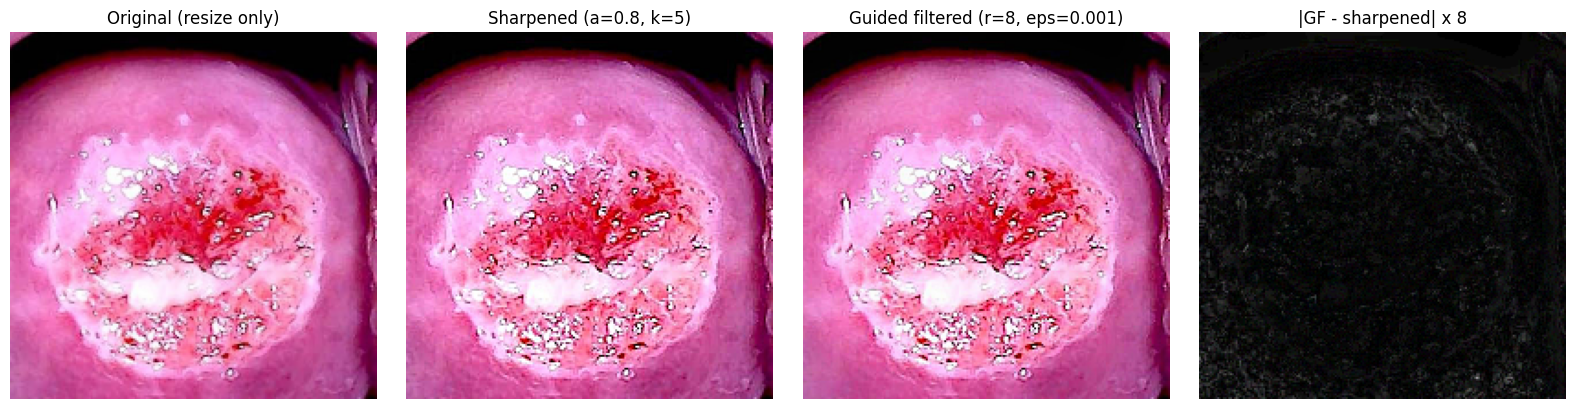

In [6]:
# ============================================================
# Cell 3.2 -- Pipeline preview: original -> sharpen -> guided filter
#             (Part A visual check only; Part B stays tables-only.)
# ============================================================
_o = X_raw[0]                                  # resize-only (before sharpen)
_s = X_base[0]                                 # after Step-1 sharpen
_g = gf_preprocess(_s, GF_DEFAULTS)            # after Step-2 guided filter
_diff = np.abs(_g.astype(np.int16) - _s.astype(np.int16)).astype(np.uint8)

print(f"Preview frame 0 | mean|GF - sharpened| = {_diff.mean():.3f}  "
      f"| max|GF - sharpened| = {_diff.max()}")

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
ax[0].imshow(_o); ax[0].set_title("Original (resize only)");        ax[0].axis("off")
ax[1].imshow(_s); ax[1].set_title(f"Sharpened (a={SHARPEN_AMOUNT}, k={SHARPEN_KSIZE})"); ax[1].axis("off")
ax[2].imshow(_g); ax[2].set_title(f"Guided filtered (r={GF_RADIUS}, eps={GF_EPS})");     ax[2].axis("off")
ax[3].imshow(_diff * 8, cmap="gray"); ax[3].set_title("|GF - sharpened| x 8"); ax[3].axis("off")
plt.tight_layout(); plt.show()


# Part B — table-only validation with 11 metrics

Single-patient, clustered frames (dHash). The frames are NOT independent.
Descriptive only — no p-values, no robustness or population claims.

**Technique:** Guided Filtering (GF; sharpen → self-guided luma guided
filter). The QI-SABP technique row and all of its ablation variants are
gone; only the GF row and the Identity reference row remain.

**Metrics:** 11 metrics in 5 groups (fidelity, colour, diagnostic
structure, quality, cost). All computed inside the FOV mask only, per
image, against the ORIGINAL image:

| #  | Metric               | Group     | Better  |
|----|----------------------|-----------|---------|
| m1 | PSNR (dB)            | fidelity  | up      |
| m2 | SSIM                 | fidelity  | up      |
| m3 | CIE76 dE (ΔE76)      | colour    | down    |
| m4 | a* correlation       | colour    | up      |
| m5 | \|a* shift\|         | colour    | down    |
| m6 | Vessel Dice          | structure | up      |
| m7 | Edge IoU             | structure | up      |
| m8 | Sharpness ratio      | quality   | neutral |
| m9 | Noise ratio          | quality   | down    |
| m10| Saturation ratio     | quality   | neutral |
| m11| Luma bits (entropy)  | cost      | down    |

The former m12 (Time, ms) is no longer a validation metric; the run cell
prints the mean processing time as run information only.

**Tables only.** No figures, no plots. T1 (main), T7 (paired CIs +
meaningful flag), T6 (caveats).

The QI-SABP-suite `cache_hash` freeze (`12f68b681210`) is **removed**:
Part A has been rewritten from QI-SABP to Guided Filtering, so the old
frozen-input assert no longer applies.


In [7]:
# ============================================================
# Step 4.1 -- Freeze inputs: FOV masks, dHash cluster ids.
#              (The cache_hash assert is REMOVED: Part A was rewritten
#               from QI-SABP to Guided Filtering, so the old frozen hash
#               12f68b681210 no longer applies.)
# ============================================================
import numpy as np
import pandas as pd
import cv2
import time
from scipy import ndimage
from skimage.metrics import structural_similarity as _ssim_fn
from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn

def _dhash_step4(gray):
    g = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()

def _compute_fov_step4(img_rgb, thr=15):
    """FOV mask: largest bright connected region, holes + frame notches
    filled (convex hull intersected with the bright region's bounding box,
    then closed with a 5 px disk)."""
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    # Convex-hull fill of frame notches
    ys, xs = np.where(fov)
    if len(ys) >= 3:
        pts = np.stack([xs, ys], axis=1).astype(np.int32)
        hull = cv2.convexHull(pts)
        hull_mask = np.zeros(g.shape, dtype=np.uint8)
        cv2.fillConvexPoly(hull_mask, hull, 1)
        hull_mask = hull_mask.astype(bool)
        x0, x1 = int(xs.min()), int(xs.max())
        y0, y1 = int(ys.min()), int(ys.max())
        bbox = np.zeros(g.shape, dtype=bool)
        bbox[y0:y1+1, x0:x1+1] = True
        hull_mask = hull_mask & bbox
        ksize = 11
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
        hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                      cv2.MORPH_CLOSE, kernel).astype(bool)
        fov = fov | hull_mask
    return fov

# ---- Freeze the validated stacks ----
images = X_base      # (N, 200, 200, 3) uint8 RGB, sharpened  (technique input)
images_raw = X_raw   # (N, 200, 200, 3) uint8 RGB, resize-only (FOV source)
n_images = len(images)
image_id = np.array([f"img_{i:04d}" for i in range(n_images)], dtype=object)
fov = np.stack([_compute_fov_step4(images_raw[i]) for i in range(n_images)])

# dHash clustering: near-duplicate frames share a cluster id, so the
# aggregation in Step 4.6 averages WITHIN a cluster first.
hs = [_dhash_step4(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY)) for i in range(n_images)]
cluster_ids = np.full(n_images, -1, dtype=int)
_next = 0
for i, h in enumerate(hs):
    if cluster_ids[i] >= 0:
        continue
    cluster_ids[i] = _next
    for j in range(i + 1, n_images):
        if cluster_ids[j] < 0 and (h != hs[j]).sum() <= 4:
            cluster_ids[j] = _next
    _next += 1
n_clusters = len(np.unique(cluster_ids))
cluster_reps = np.array([np.where(cluster_ids == uc)[0][0]
                          for uc in np.unique(cluster_ids)], dtype=int)

print(f"Inputs frozen: n_images = {n_images} | n_clusters (dHash) = {n_clusters} "
      f"| n_distinct = {len(cluster_reps)}")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct clusters "
      f"from one patient). All tables say this.")


Inputs frozen: n_images = 128 | n_clusters (dHash) = 7 | n_distinct = 7
  The 128 frames are NOT independent (7 distinct clusters from one patient). All tables say this.


In [8]:
# ============================================================
# Step 4.2 -- step4_validator + helper functions. Computes 11 metrics
#             inside the FOV only, per image.
# ============================================================

def _vessel_map(img_rgb):
    """Frangi vessel filter -> vessel probability map (0-1)."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    try:
        from skimage.filters import frangi
        v = frangi(gray, black_ridges=False)
        v = v / (v.max() + 1e-8)
    except Exception:
        # Fallback: Sobel-based ridge detection
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
        v = np.hypot(gx, gy)
        v = v / (v.max() + 1e-8)
    return v.astype(np.float32)

def _vessel_dice(original, processed, fov_mask, top_pct=10):
    """Dice of the top `top_pct` Frangi vessel pixels inside the FOV.
    Binarizes each vessel map at the (100 - top_pct) percentile inside
    the FOV, then computes the Dice coefficient 2*|A∩B|/(|A|+|B|).
    """
    f = np.asarray(fov_mask, dtype=bool)
    v_o = _vessel_map(original)[f]
    v_p = _vessel_map(processed)[f]
    thr_o = np.percentile(v_o, 100 - top_pct)
    thr_p = np.percentile(v_p, 100 - top_pct)
    b_o = v_o >= thr_o
    b_p = v_p >= thr_p
    inter = float((b_o & b_p).sum())
    size_o = float(b_o.sum())
    size_p = float(b_p.sum())
    denom = size_o + size_p
    if denom == 0:
        return float('nan')
    return 2.0 * inter / denom

def _edge_map(img_rgb):
    """Canny edge binary map."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    return (edges > 0).astype(np.uint8)

def _pearson_corr(a, b, mask):
    """Pearson correlation inside the mask."""
    a = a[mask].astype(np.float64)
    b = b[mask].astype(np.float64)
    if len(a) < 2 or a.std() < 1e-9 or b.std() < 1e-9:
        return float('nan')
    return float(np.corrcoef(a, b)[0, 1])

def _edge_iou(a_edges, b_edges, mask):
    """IoU of two edge maps inside the mask."""
    a = a_edges[mask].astype(bool)
    b = b_edges[mask].astype(bool)
    u = (a | b).sum()
    if u == 0:
        return float('nan')
    return float((a & b).sum() / u)

def _specular_mask(img_rgb):
    """Specular/glare mask (V >= 250 and S <= 25)."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    return ((hsv[..., 2] >= 250) & (hsv[..., 1] <= 25)).astype(bool)

def _luma_entropy_bits(img_rgb, fov_mask):
    """First-order Shannon entropy of the luma histogram inside the FOV.

    This replaces the QI-SABP analytic bit-map mean: guided filtering has
    no bit allocation, so 'Luma bits' is defined as the bits/px a
    memoryless coder would need to encode the processed luma channel.
    """
    f = np.asarray(fov_mask, dtype=bool)
    ycc = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2YCrCb)
    vals = ycc[..., 0][f]
    if vals.size == 0:
        return float('nan')
    hist = np.bincount(vals.ravel(), minlength=256).astype(np.float64)
    p = hist / hist.sum()
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

def step4_validator(original, processed, fov_mask):
    """Compute 11 metrics inside the FOV only, per image.

    Returns a dict with keys m1..m11:
      m1  PSNR (dB)                    up
      m2  SSIM                         up
      m3  CIE76 dE                     down
      m4  a* correlation               up
      m5  |mean a* shift|              down
      m6  Vessel Dice (top 10%)        up
      m7  Edge IoU                     up
      m8  Sharpness ratio (out/in)     neutral (0.9-1.1)
      m9  Noise ratio (out/in)         down
      m10 Saturation ratio (out/in)    neutral (at most 1)
      m11 Luma bits (Y entropy, FOV)   down (cost)

    All metrics are computed against the ORIGINAL image. The former m12
    (Time, ms) is no longer a validation metric.
    """
    f = np.asarray(fov_mask, dtype=bool)
    o = np.asarray(original, dtype=np.float32)
    p = np.asarray(processed, dtype=np.float32)
    # m1: PSNR (dB)
    mse = float(((o - p) ** 2)[f].mean())
    m1 = 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-10))
    # m2: SSIM (FOV-masked)
    ssim_map = _ssim_fn(original, processed, channel_axis=2,
                         full=True, data_range=255)[1]
    m2 = float(ssim_map.mean(2)[f].mean())
    # m3: CIE76 dE (stating which: CIE76)
    m3 = float(_deltaE_fn(_rgb2lab_fn(original), _rgb2lab_fn(processed))[f].mean())
    # m4: a* correlation
    lab_o = _rgb2lab_fn(original)
    lab_p = _rgb2lab_fn(processed)
    m4 = _pearson_corr(lab_o[..., 1], lab_p[..., 1], f)
    # m5: |mean a* shift|
    a_o = float(lab_o[..., 1][f].mean())
    a_p = float(lab_p[..., 1][f].mean())
    m5 = abs(a_p - a_o)
    # m6: Vessel Dice (top 10% Frangi pixels)
    m6 = _vessel_dice(original, processed, f, top_pct=10)
    # m7: Edge IoU
    e_o = _edge_map(original)
    e_p = _edge_map(processed)
    m7 = _edge_iou(e_o, e_p, f)
    # m8: Sharpness ratio (Laplacian variance, out/in)
    g_o = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    g_p = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    lap_o = float(cv2.Laplacian(g_o, cv2.CV_64F)[f].var())
    lap_p = float(cv2.Laplacian(g_p, cv2.CV_64F)[f].var())
    m8 = lap_p / max(lap_o, 1e-9)
    # m9: Noise ratio (out/in) -- 1.4826 * MAD of the high-pass, measured
    # in the smoothest 30% of FOV pixels (by Sobel gradient magnitude)
    hp_o = g_o.astype(np.float32) - cv2.GaussianBlur(g_o.astype(np.float32), (0, 0), 1.5)
    hp_p = g_p.astype(np.float32) - cv2.GaussianBlur(g_p.astype(np.float32), (0, 0), 1.5)
    gm = np.hypot(cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 1, 0),
                   cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 0, 1))
    smooth = f & (gm < np.percentile(gm[f], 30))
    if smooth.any():
        noise_o = float(1.4826 * np.median(np.abs(hp_o[smooth] - np.median(hp_o[smooth]))))
        noise_p = float(1.4826 * np.median(np.abs(hp_p[smooth] - np.median(hp_p[smooth]))))
        m9 = noise_p / max(noise_o, 1e-9)
    else:
        m9 = float('nan')
    # m10: Saturation ratio (output specular / input specular). Measures
    # NEW saturation introduced by the technique; ratio <= 1 is good.
    sp_o = _specular_mask(original)
    sp_p = _specular_mask(processed)
    m10 = float(sp_p[f].sum()) / max(float(sp_o[f].sum()), 1e-9)
    # m11: Luma bits (first-order Y entropy inside the FOV, bits/px)
    m11 = _luma_entropy_bits(processed, f)
    return dict(m1=m1, m2=m2, m3=m3, m4=m4, m5=m5, m6=m6, m7=m7,
                m8=m8, m9=m9, m10=m10, m11=m11)

# Metric metadata (key, name, group, better direction)
METRIC_META = [
    ("m1",  "PSNR (dB)",           "fidelity",  "up"),
    ("m2",  "SSIM",                "fidelity",  "up"),
    ("m3",  "CIE76 dE",            "colour",    "down"),
    ("m4",  "a* corr",             "colour",    "up"),
    ("m5",  "|a* shift|",          "colour",    "down"),
    ("m6",  "Vessel Dice",         "structure", "up"),
    ("m7",  "Edge IoU",            "structure", "up"),
    ("m8",  "Sharpness ratio",     "quality",   "neutral"),
    ("m9",  "Noise ratio",         "quality",   "down"),
    ("m10", "Saturation ratio",    "quality",   "neutral"),
    ("m11", "Luma bits (entropy)", "cost",      "down"),
]
METRIC_KEYS = [m[0] for m in METRIC_META]
METRIC_NAMES = {m[0]: m[1] for m in METRIC_META}
METRIC_GROUPS = {m[0]: m[2] for m in METRIC_META}
METRIC_BETTER = {m[0]: m[3] for m in METRIC_META}
print("step4_validator ready: 11 metrics (m1..m11).")


step4_validator ready: 11 metrics (m1..m11).


In [9]:
# ============================================================
# Step 4.3 -- Compute 11 metrics for Guided Filtering + Identity
#             reference. Write per-image CSVs. Cache processed images.
# ============================================================
import os as _os
import glob as _glob

for _old in _glob.glob("results_*.csv"):
    _os.remove(_old)
    print(f"  Deleted stale {_old}")

processed_cache = {}   # (technique, image_idx) -> uint8 RGB

def _run_technique(name, fn):
    """Run one technique over all frames; returns per-image metric rows."""
    rows = []
    t_run0 = time.perf_counter()
    for i in range(n_images):
        orig = images[i]
        fov_i = fov[i]
        t0 = time.perf_counter()
        proc = fn(orig, i)
        elapsed_ms = (time.perf_counter() - t0) * 1000
        m = step4_validator(orig, proc, fov_i)
        m["technique"] = name
        m["image_id"] = image_id[i]
        m["cluster_id"] = int(cluster_ids[i])
        m["_elapsed_ms"] = elapsed_ms
        rows.append(m)
        processed_cache[(name, i)] = proc.copy()
        if (i + 1) % 50 == 0 or i == n_images - 1:
            print(f"  {name}: processed {i + 1}/{n_images} frames...")
    total_s = time.perf_counter() - t_run0
    mean_ms = float(np.mean([r["_elapsed_ms"] for r in rows]))
    print(f"  {name}: mean {mean_ms:.1f} ms/frame | total {total_s:.1f} s "
          f"(informational only, not a validation metric)")
    return rows

TECHNIQUE = "Guided Filtering"
rows_gf = _run_technique(TECHNIQUE,
                         lambda img, i: gf_preprocess(img, GF_DEFAULTS, seed=42 + i))
df_gf = pd.DataFrame(rows_gf)
GF_CSV = "results_GuidedFiltering.csv"
df_gf.to_csv(GF_CSV, index=False)
print(f"Wrote {GF_CSV} ({len(df_gf)} rows)")
print(f"  Mean luma bits (GF) = {df_gf['m11'].mean():.3f}")

# Identity reference: processed == original (ideal values; sanity row only).
rows_id = _run_technique("Identity", lambda img, i: img.copy())
df_id = pd.DataFrame(rows_id)
df_id.to_csv("results_Identity.csv", index=False)
print(f"Wrote results_Identity.csv ({len(df_id)} rows)")
print(f"  Mean luma bits (Identity) = {df_id['m11'].mean():.3f} "
      f"(= original-image luma entropy, as expected)")


  Deleted stale results_Gabor.csv
  Deleted stale results_Gamma_Correction.csv
  Deleted stale results_Identity.csv
  Guided Filtering: processed 50/128 frames...
  Guided Filtering: processed 100/128 frames...
  Guided Filtering: processed 128/128 frames...
  Guided Filtering: mean 1.8 ms/frame | total 45.2 s (informational only, not a validation metric)
Wrote results_GuidedFiltering.csv (128 rows)
  Mean luma bits (GF) = 7.639
  Identity: processed 50/128 frames...
  Identity: processed 100/128 frames...
  Identity: processed 128/128 frames...
  Identity: mean 0.0 ms/frame | total 47.5 s (informational only, not a validation metric)
Wrote results_Identity.csv (128 rows)
  Mean luma bits (Identity) = 7.659 (= original-image luma entropy, as expected)


In [14]:
# ============================================================
# STEP 4.4: MERGE TECHNIQUE CSV FILES
# Techniques: Shades-of-Gray and Identity
# Fixed file list (no glob)
#
# Fixes:
#   1. Does not rely on stale global cluster_ids.
#   2. Validates cluster IDs between the two CSVs.
#   3. Handles different CSV row orders.
#   4. Checks row counts, metric columns, and NaN values.
#   5. Saves the merged CSV.
# ============================================================

from pathlib import Path
import re
import pandas as pd

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

RESULTS_DIR = Path(r"C:\CER")

CSV_FILES = {
    "Shades-of-Gray": RESULTS_DIR / "results_Shades-of-Gray.csv",
    "Identity": RESULTS_DIR / "results_Identity.csv",
}

OUTPUT_FILE = (
    RESULTS_DIR / "results_merged_shades_gray_identity.csv"
)

print("=" * 70)
print("STEP 4.4: MERGE TECHNIQUE CSV FILES")
print("=" * 70)
print(f"Results directory: {RESULTS_DIR}")
print(f"Current working directory: {Path.cwd()}")
print("Techniques: Shades-of-Gray, Identity")


# ------------------------------------------------------------
# 2. Check the directory and required files
# ------------------------------------------------------------

if not RESULTS_DIR.is_dir():
    raise FileNotFoundError(
        f"Results directory does not exist: {RESULTS_DIR}"
    )

missing_files = [
    str(path)
    for path in CSV_FILES.values()
    if not path.is_file()
]

if missing_files:
    raise FileNotFoundError(
        "Required CSV files are missing:\n"
        + "\n".join(missing_files)
    )


# ------------------------------------------------------------
# 3. Helper functions
# ------------------------------------------------------------

def normalize_technique(value):
    """Ignore spaces, hyphens, and capitalization."""
    return re.sub(r"[^a-z0-9]", "", str(value).lower())


def normalize_cluster_id(value):
    """
    Normalize IDs for comparison.
    Examples: 1, '1', and '1.0' become the same key.
    Text identifiers are otherwise preserved.
    """
    if pd.isna(value):
        return None

    value = str(value).strip()

    if re.fullmatch(r"[+-]?\d+\.0+", value):
        value = value.split(".")[0]

    return value


# ------------------------------------------------------------
# 4. Read the two CSV files
# ------------------------------------------------------------

loaded = {}

for expected_technique, path in CSV_FILES.items():

    df = pd.read_csv(path)

    if df.empty:
        raise ValueError(f"{path.name} is empty.")

    required_cols = {"technique", "cluster_id"}
    missing_cols = required_cols - set(df.columns)

    if missing_cols:
        raise ValueError(
            f"{path.name} is missing columns: "
            f"{sorted(missing_cols)}"
        )

    actual_techniques = (
        df["technique"].dropna().astype(str).unique().tolist()
    )

    if len(actual_techniques) != 1:
        raise ValueError(
            f"{path.name} must contain exactly one technique. "
            f"Found: {actual_techniques}"
        )

    if (
        normalize_technique(actual_techniques[0])
        != normalize_technique(expected_technique)
    ):
        raise ValueError(
            f"Technique mismatch in {path.name}: "
            f"expected '{expected_technique}', "
            f"found '{actual_techniques[0]}'."
        )

    if df["cluster_id"].isna().any():
        raise ValueError(
            f"{path.name} contains missing cluster IDs."
        )

    df = df.copy()
    df["technique"] = expected_technique

    df["_cluster_key"] = df["cluster_id"].map(
        normalize_cluster_id
    )

    if df["_cluster_key"].isna().any():
        raise ValueError(
            f"{path.name} contains invalid cluster IDs."
        )

    loaded[expected_technique] = df

    print(
        f"READ: {path.name} | "
        f"Rows: {len(df)} | "
        f"Technique: {expected_technique}"
    )


# ------------------------------------------------------------
# 5. Validate row counts
# ------------------------------------------------------------

row_counts = {
    technique: len(df)
    for technique, df in loaded.items()
}

print("\nRow counts:", row_counts)

if len(set(row_counts.values())) != 1:
    raise ValueError(
        f"Row counts differ between CSV files: {row_counts}"
    )

# Use the actual CSV contents, not a potentially stale
# notebook variable, as the source of truth.
expected_rows = len(loaded["Shades-of-Gray"])

print(f"PASS: Both CSV files have {expected_rows} rows.")


# ------------------------------------------------------------
# 6. Compare cluster IDs independently of row order
# ------------------------------------------------------------

gray_df = loaded["Shades-of-Gray"]
identity_df = loaded["Identity"]

gray_ids = sorted(gray_df["_cluster_key"].tolist())
identity_ids = sorted(identity_df["_cluster_key"].tolist())

if gray_ids != identity_ids:

    gray_set = set(gray_ids)
    identity_set = set(identity_ids)

    only_gray = sorted(gray_set - identity_set)
    only_identity = sorted(identity_set - gray_set)

    raise ValueError(
        "Cluster IDs differ between the CSV files.\n"
        f"IDs only in Shades-of-Gray: {only_gray[:20]}\n"
        f"IDs only in Identity: {only_identity[:20]}\n"
        "Check the source result files before merging."
    )

print("PASS: Both CSV files contain matching cluster IDs.")


# ------------------------------------------------------------
# 7. Sort both datasets using the same cluster ID order
# ------------------------------------------------------------

validated_dfs = []

for technique in ["Shades-of-Gray", "Identity"]:

    df = loaded[technique].copy()

    df = df.sort_values(
        by="_cluster_key",
        kind="stable"
    ).reset_index(drop=True)

    validated_dfs.append(df)

    print(f"VALIDATED: {technique}")


# ------------------------------------------------------------
# 8. Identify metric columns
# ------------------------------------------------------------

# Reuse METRIC_KEYS if defined by the earlier notebook cells.
if "METRIC_KEYS" in globals() and METRIC_KEYS:

    metric_keys = list(METRIC_KEYS)

else:

    excluded_cols = {
        "technique",
        "cluster_id",
        "image_id",
        "image_index",
        "index",
        "_cluster_key",
    }

    metric_keys = [
        col
        for col in validated_dfs[0].columns
        if col not in excluded_cols
        and pd.api.types.is_numeric_dtype(
            validated_dfs[0][col]
        )
    ]

if not metric_keys:
    raise ValueError(
        "No metric columns were found. "
        "Check METRIC_KEYS or the CSV column names."
    )

for technique, df in zip(
    ["Shades-of-Gray", "Identity"],
    validated_dfs
):

    missing_metrics = set(metric_keys) - set(df.columns)

    if missing_metrics:
        raise ValueError(
            f"{technique} is missing metric columns: "
            f"{sorted(missing_metrics)}"
        )

print(f"\nMetric columns checked: {len(metric_keys)}")


# ------------------------------------------------------------
# 9. Check missing metric values
# ------------------------------------------------------------

all_metric_nan_counts = {}

for technique, df in zip(
    ["Shades-of-Gray", "Identity"],
    validated_dfs
):

    nan_counts = df[metric_keys].isna().sum()
    nan_counts = nan_counts[nan_counts > 0]

    if not nan_counts.empty:
        all_metric_nan_counts[technique] = (
            nan_counts.to_dict()
        )

if all_metric_nan_counts:
    raise ValueError(
        "NaN values found in metric columns:\n"
        f"{all_metric_nan_counts}"
    )

print("PASS: No NaN values in the metric columns.")


# ------------------------------------------------------------
# 10. Concatenate the validated CSV files
# ------------------------------------------------------------

merged = pd.concat(
    validated_dfs,
    ignore_index=True
)

# Remove the internal comparison key from the output.
merged.drop(columns=["_cluster_key"], inplace=True)

expected_techniques = {"Shades-of-Gray", "Identity"}
actual_techniques = set(merged["technique"].unique())

if actual_techniques != expected_techniques:
    raise ValueError(
        f"Unexpected techniques in merged CSV: "
        f"{sorted(actual_techniques)}"
    )

expected_total_rows = expected_rows * 2

if len(merged) != expected_total_rows:
    raise ValueError(
        f"Expected {expected_total_rows} merged rows, "
        f"found {len(merged)}."
    )


# ------------------------------------------------------------
# 11. Save the merged output
# ------------------------------------------------------------

merged.to_csv(OUTPUT_FILE, index=False)

print("\n" + "=" * 70)
print("STEP 4.4 COMPLETED SUCCESSFULLY")
print("=" * 70)

print(f"Techniques: {sorted(actual_techniques)}")
print(f"Rows per technique: {expected_rows}")
print(f"Total merged rows: {len(merged)}")
print(f"Metric columns: {len(metric_keys)}")
print(f"Saved file: {OUTPUT_FILE}")
print(f"Final shape: {merged.shape}")

display(merged.head())

STEP 4.4: MERGE TECHNIQUE CSV FILES
Results directory: C:\CER
Current working directory: C:\CER
Techniques: Shades-of-Gray, Identity
READ: results_Shades-of-Gray.csv | Rows: 128 | Technique: Shades-of-Gray
READ: results_Identity.csv | Rows: 128 | Technique: Identity

Row counts: {'Shades-of-Gray': 128, 'Identity': 128}
PASS: Both CSV files have 128 rows.
PASS: Both CSV files contain matching cluster IDs.
VALIDATED: Shades-of-Gray
VALIDATED: Identity

Metric columns checked: 11
PASS: No NaN values in the metric columns.

STEP 4.4 COMPLETED SUCCESSFULLY
Techniques: ['Identity', 'Shades-of-Gray']
Rows per technique: 128
Total merged rows: 256
Metric columns: 11
Saved file: C:\CER\results_merged_shades_gray_identity.csv
Final shape: (256, 16)


,m1,m2,m3,m4,m5,m6,m7,m8,m9,m10,m11,elapsed_ms,total_bits,technique,image_id,cluster_id
0,28.038524,0.98404,7.058442,0.974328,5.796155,0.910633,0.789572,1.05185,0.931053,1.302692,8.0,5.9716,8.0,Shades-of-Gray,img_0000,0
1,28.038524,0.98404,7.058442,0.974328,5.796155,0.910633,0.789572,1.05185,0.931053,1.302692,8.0,4.7160,8.0,Shades-of-Gray,img_0001,0
2,28.038524,0.98404,7.058442,0.974328,5.796155,0.910633,0.789572,1.05185,0.931053,1.302692,8.0,3.7965,8.0,Shades-of-Gray,img_0002,0
3,28.038524,0.98404,7.058442,0.974328,5.796155,0.910633,0.789572,1.05185,0.931053,1.302692,8.0,5.1840,8.0,Shades-of-Gray,img_0003,0
4,28.038524,0.98404,7.058442,0.974328,5.796155,0.910633,0.789572,1.05185,0.931053,1.302692,8.0,4.7899,8.0,Shades-of-Gray,img_0004,0


In [16]:
# ============================================================
# STEP 4.5 -- Aggregation
# Average within each cluster first, then across clusters.
# 95% CI using cluster bootstrap (2000 resamples, fixed seed).
#
# Label: "within-patient, N clusters, not a population CI"
# ============================================================

import numpy as np
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

# Explicitly define techniques from Step 4.4.
techniques = ["Shades-of-Gray", "Identity"]

N_BOOT = 2000
BOOTSTRAP_SEED = 42

if "merged" not in globals():
    raise NameError(
        "The variable 'merged' is missing. "
        "Run Step 4.4 successfully before Step 4.5."
    )

required_columns = {"technique", "cluster_id"}
missing_columns = required_columns - set(merged.columns)

if missing_columns:
    raise ValueError(
        f"Merged dataset is missing columns: "
        f"{sorted(missing_columns)}"
    )

actual_techniques = set(merged["technique"].dropna().unique())

if actual_techniques != set(techniques):
    raise ValueError(
        f"Technique mismatch. Expected {techniques}; "
        f"found {sorted(actual_techniques)}."
    )


# ------------------------------------------------------------
# 2. Determine metric columns
# ------------------------------------------------------------

# Use the metric list from earlier notebook cells if available.
if "METRIC_KEYS" in globals() and METRIC_KEYS:
    metric_keys = list(METRIC_KEYS)
else:
    excluded_columns = {
        "technique",
        "cluster_id",
        "image_id",
        "image_index",
        "index",
    }

    metric_keys = [
        col
        for col in merged.columns
        if col not in excluded_columns
        and pd.api.types.is_numeric_dtype(merged[col])
    ]

if not metric_keys:
    raise ValueError(
        "No metric columns found. Define METRIC_KEYS "
        "or verify the merged CSV column names."
    )

missing_metrics = set(metric_keys) - set(merged.columns)

if missing_metrics:
    raise ValueError(
        f"Missing metric columns: {sorted(missing_metrics)}"
    )

# Ensure metrics contain numeric values and no missing data.
for metric in metric_keys:
    merged[metric] = pd.to_numeric(
        merged[metric],
        errors="raise"
    )

if merged[metric_keys].isna().any().any():
    raise ValueError(
        "NaN values found in metric columns. "
        "Resolve them before aggregation."
    )

print("=" * 70)
print("STEP 4.5: CLUSTER-WEIGHTED AGGREGATION")
print("=" * 70)
print("Techniques:", techniques)
print("Metrics:", len(metric_keys))
print("Bootstrap resamples:", N_BOOT)
print("Bootstrap seed:", BOOTSTRAP_SEED)


# ------------------------------------------------------------
# 3. Create consistent cluster IDs
# ------------------------------------------------------------

def normalize_cluster_id(value):
    """Normalize common numeric ID representations."""
    if pd.isna(value):
        raise ValueError("Missing cluster_id found.")

    value = str(value).strip()

    # Make '1.0' and '1' equivalent.
    if value.endswith(".0") and value[:-2].lstrip("-").isdigit():
        value = value[:-2]

    return value


work_df = merged.copy()
work_df["_cluster_key"] = work_df["cluster_id"].map(
    normalize_cluster_id
)

if work_df["_cluster_key"].isna().any():
    raise ValueError("Missing cluster identifiers detected.")


# ------------------------------------------------------------
# 4. Check cluster consistency across techniques
# ------------------------------------------------------------

cluster_sets = {}

for tech in techniques:
    tech_df = work_df[work_df["technique"] == tech]

    cluster_sets[tech] = set(tech_df["_cluster_key"].unique())

    print(
        f"{tech}: {len(tech_df)} rows, "
        f"{len(cluster_sets[tech])} unique clusters"
    )

if cluster_sets[techniques[0]] != cluster_sets[techniques[1]]:
    only_first = sorted(
        cluster_sets[techniques[0]] - cluster_sets[techniques[1]]
    )
    only_second = sorted(
        cluster_sets[techniques[1]] - cluster_sets[techniques[0]]
    )

    raise ValueError(
        "Cluster IDs differ across techniques.\n"
        f"Only in {techniques[0]}: {only_first[:20]}\n"
        f"Only in {techniques[1]}: {only_second[:20]}"
    )

n_clusters = len(cluster_sets[techniques[0]])

if n_clusters == 0:
    raise ValueError("No clusters available for aggregation.")

print(f"\nNumber of matched clusters: {n_clusters}")


# ------------------------------------------------------------
# 5. Cluster-weighted mean
# ------------------------------------------------------------

def _cluster_mean(tech_df, metric_key):
    """
    First average observations within each cluster.
    Then average cluster means, giving each cluster equal weight.
    """
    cluster_means = (
        tech_df.groupby("_cluster_key", sort=True)[metric_key]
        .mean()
    )

    if cluster_means.empty:
        return float("nan")

    return float(cluster_means.mean())


# ------------------------------------------------------------
# 6. Cluster-bootstrap 95% confidence interval
# ------------------------------------------------------------

def _cluster_bootstrap_ci(
    tech_df,
    metric_key,
    n_boot=N_BOOT,
    seed=BOOTSTRAP_SEED,
):
    """
    Bootstrap clusters, not individual rows.

    Returns:
        mean, lower 95% percentile CI, upper 95% percentile CI

    Interpretation follows the requested within-patient /
    observed-cluster analysis, not a population CI.
    """
    cluster_means = (
        tech_df.groupby("_cluster_key", sort=True)[metric_key]
        .mean()
    )

    values = cluster_means.to_numpy(dtype=float)
    n = len(values)

    if n == 0:
        return float("nan"), float("nan"), float("nan")

    observed_mean = float(np.mean(values))

    if n < 2:
        return observed_mean, float("nan"), float("nan")

    rng = np.random.default_rng(seed)

    # Sample clusters with replacement.
    bootstrap_means = np.empty(n_boot, dtype=float)

    for b in range(n_boot):
        sampled_indices = rng.integers(
            low=0,
            high=n,
            size=n,
        )

        bootstrap_means[b] = values[sampled_indices].mean()

    ci_lo, ci_hi = np.percentile(
        bootstrap_means,
        [2.5, 97.5],
    )

    return (
        observed_mean,
        float(ci_lo),
        float(ci_hi),
    )


# ------------------------------------------------------------
# 7. Aggregate every technique and metric
# ------------------------------------------------------------

agg_rows = []

for tech_index, tech in enumerate(techniques):

    tech_df = work_df[
        work_df["technique"] == tech
    ].copy()

    row = {
        "technique": tech,
        "n_clusters": tech_df["_cluster_key"].nunique(),
    }

    for metric_index, metric in enumerate(metric_keys):

        # Deterministic but distinct seed for each metric.
        metric_seed = BOOTSTRAP_SEED + metric_index

        mean, lo, hi = _cluster_bootstrap_ci(
            tech_df=tech_df,
            metric_key=metric,
            n_boot=N_BOOT,
            seed=metric_seed,
        )

        row[metric] = mean
        row[f"{metric}_lo"] = lo
        row[f"{metric}_hi"] = hi

    agg_rows.append(row)


# ------------------------------------------------------------
# 8. Create aggregation DataFrame
# ------------------------------------------------------------

agg_df = pd.DataFrame(agg_rows).set_index("technique")

print("\nAggregation done: cluster-weighted mean + 95% CI.")
print(
    f"WITHIN-PATIENT, {n_clusters} clusters, "
    "NOT a population CI."
)

display(agg_df)


# ------------------------------------------------------------
# 9. Save aggregation summary
# ------------------------------------------------------------

OUTPUT_FILE = Path(r"C:\CER\metrics_summary_cluster_bootstrap.csv")

agg_df.to_csv(OUTPUT_FILE)

print("\nSTEP 4.5 COMPLETED SUCCESSFULLY")
print(f"Saved aggregation summary: {OUTPUT_FILE}")

STEP 4.5: CLUSTER-WEIGHTED AGGREGATION
Techniques: ['Shades-of-Gray', 'Identity']
Metrics: 11
Bootstrap resamples: 2000
Bootstrap seed: 42
Shades-of-Gray: 128 rows, 6 unique clusters
Identity: 128 rows, 6 unique clusters

Number of matched clusters: 6

Aggregation done: cluster-weighted mean + 95% CI.
WITHIN-PATIENT, 6 clusters, NOT a population CI.


,n_clusters,m1,m1_lo,m1_hi,m2,m2_lo,m2_hi,m3,m3_lo,m3_hi,...,m8_hi,m9,m9_lo,m9_hi,m10,m10_lo,m10_hi,m11,m11_lo,m11_hi
technique,,,,,,,,,,,,,,,,,,,,,
Shades-of-Gray,6,28.381316,28.045893,28.737200,0.982559,0.980524,0.984552,6.941967,6.807169,7.074385,...,1.066151,0.895006,0.86708,0.919228,1.274157,1.261034,1.288083,8.0,8.0,8.0
Identity,6,148.130804,148.130804,148.130804,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,...,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,8.0,8.0,8.0



STEP 4.5 COMPLETED SUCCESSFULLY
Saved aggregation summary: C:\CER\metrics_summary_cluster_bootstrap.csv


In [17]:
# ============================================================
# Step 4.6 -- Statistics: Guided Filtering vs the Identity reference,
#              per key metric. Uses paired difference per cluster
#              (one value per cluster) + bootstrap CI. Reports
#              "CI excludes 0: yes/no". Descriptive, no significance
#              claim.
# ============================================================

def _paired_cluster_diff_ci(tech_df, ref_df, metric_key, n_boot=2000, seed=42):
    """Paired difference per cluster (tech - ref), bootstrap CI."""
    tech_cm = tech_df.groupby("cluster_id")[metric_key].mean()
    ref_cm = ref_df.groupby("cluster_id")[metric_key].mean()
    diff = (tech_cm - ref_cm).values
    if len(diff) < 2:
        return float('nan'), float('nan'), float('nan'), False
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(diff), size=len(diff))
        boots.append(diff[idx].mean())
    boots = np.array(boots)
    lo, hi = float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))
    excludes = (lo > 0) or (hi < 0)
    return float(diff.mean()), lo, hi, excludes

# Key metrics for the paired comparison (skip PSNR/SSIM/luma-bits vs
# Identity -- they are meaningless against a copy of the input).
key_metrics = ["m3", "m5", "m6", "m7", "m9"]

stat_rows = []
gf_df = merged[merged["technique"] == "Guided Filtering"]
id_df = merged[merged["technique"] == "Identity"]
for mk in key_metrics:
    md, lo, hi, ex = _paired_cluster_diff_ci(gf_df, id_df, mk)
    stat_rows.append({
        "metric": METRIC_NAMES[mk],
        "comparison": "Guided Filtering vs Identity",
        "mean_diff": md, "ci_lo": lo, "ci_hi": hi,
        "CI_excludes_0": "yes" if ex else "no",
    })

stat_df = pd.DataFrame(stat_rows)
print("Statistics done. Guided Filtering vs Identity, key metrics only.")
print(f"  Descriptive, no significance claim. {n_clusters} clusters, within-patient.")


Statistics done. Guided Filtering vs Identity, key metrics only.
  Descriptive, no significance claim. 6 clusters, within-patient.


In [18]:
# ============================================================
# Step 4.7 -- Print tables T1, T7, T6.
#   T2 (ranks), T3 (Pareto), T4 (ablation), T5 (per-cluster mask split)
#   and T8 (region split) are REMOVED: they compared QI-SABP against its
#   mask variants and relied on the QI-SABP hard mask, all of which are
#   gone with the QI-SABP pipeline.
# ============================================================

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 50)

# ---- T1 Main ----
print("=" * 130)
print(f"T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, {n_clusters} clusters, "
      f"NOT a population CI)")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct clusters "
      f"from one patient).")
print("  Identity is a reference row (ideal values, not ranked).")
print("=" * 130)
t1_rows = []
for tech in techniques:
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean = agg_df.loc[tech, mk]
        lo = agg_df.loc[tech, f"{mk}_lo"]
        hi = agg_df.loc[tech, f"{mk}_hi"]
        row[METRIC_NAMES[mk]] = f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"
    t1_rows.append(row)
t1_df = pd.DataFrame(t1_rows).set_index("technique")
arrow_map = {"up": "^", "down": "v", "neutral": "o"}
t1_headers = {METRIC_NAMES[mk]: f"{METRIC_NAMES[mk]} ({arrow_map[METRIC_BETTER[mk]]})"
              for mk in METRIC_KEYS}
print(t1_df.rename(columns=t1_headers).to_string())

# ---- T7 Paired CIs + meaningful flag ----
print()
print("=" * 130)
print("T7 PAIRED CIs  (Guided Filtering vs Identity; key metrics; CI excludes 0; meaningful flag)")
print("  Meaningful thresholds: dE >= 0.5, |a*| >= 0.2, Dice >= 0.01, IoU >= 0.02, noise >= 0.05")
print("=" * 130)
_meaningful_thresh = {"CIE76 dE": 0.5, "|a* shift|": 0.2, "Vessel Dice": 0.01,
                      "Edge IoU": 0.02, "Noise ratio": 0.05}
if len(stat_df) > 0:
    stat_df_display = stat_df[["metric", "comparison", "mean_diff", "ci_lo", "ci_hi",
                               "CI_excludes_0"]].copy()
    stat_df_display["meaningful"] = stat_df_display.apply(
        lambda r: "yes" if abs(r["mean_diff"]) >= _meaningful_thresh.get(r["metric"], 0) else "no",
        axis=1)
    print(stat_df_display.round(4).to_string(index=False))
else:
    print("  (no statistics computed)")

# ---- T6 Caveats ----
print()
print("=" * 130)
print("T6 CAVEATS  (one line each)")
print("=" * 130)
_n_lesion = int(masks.any((1, 2)).sum())
caveats = [
    f"Single patient; {n_clusters} distinct frames (dHash); {n_images} frames NOT independent.",
    "Descriptive only; no p-values; no robustness or population claims.",
    f"Lesion masks matched: {_n_lesion}/{len(masks)}; lesion-restricted metrics are not evaluated.",
    "Technique: Guided Filtering = Step-1 unsharp sharpen (0.8, k5) -> self-guided luma guided "
    "filter (radius 8, eps 1e-3 on the 0-1 intensity scale); Cb/Cr untouched (luma-only mode).",
    "Luma bits (m11) is the FIRST-ORDER Shannon entropy of the processed luma histogram inside "
    "the FOV (bits/px for a memoryless coder) -- NOT a bit allocation (QI-SABP is removed). "
    "Identity equals the original-image luma entropy.",
    "Identity is a reference row only (not ranked). Its dE=0, Dice=1.0, IoU=1.0 and the ~148 dB "
    "PSNR are ideal values.",
    f"95% CI is WITHIN-PATIENT, {n_clusters} clusters, NOT a population CI.",
    "CIE76 dE (not CIEDE2000).",
    "Metric 8 (sharpness ratio) and metric 10 (saturation ratio) are neutral, not ranked.",
    "Edge IoU (m7) PENALISES denoising: Canny edges from noise vanish when noise is removed, so "
    "a lower IoU does not mean lost anatomy.",
    "Vessel Dice (m6): Dice of top 10% Frangi pixels, 2*|A∩B|/(|A|+|B|).",
    "eps uses the reference implementation's 0-1 intensity convention (pixels are divided by 255 "
    "before filtering and rescaled afterwards).",
    "Guided Filtering is deterministic: no seed, no dither, no stochastic post-processing; the "
    "per-image seed argument exists only for validator API compatibility.",
    "Time per frame is printed by the run cell as information only and is NOT a validation metric.",
    "T7 meaningful flag: dE >= 0.5, |a*| >= 0.2, Dice >= 0.01, IoU >= 0.02, noise >= 0.05. With "
    "few clusters, tiny differences 'exclude 0' but may not be practically meaningful.",
]
for c in caveats:
    print(f"  - {c}")


T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, 6 clusters, NOT a population CI)
  The 128 frames are NOT independent (6 distinct clusters from one patient).
  Identity is a reference row (ideal values, not ranked).
                             PSNR (dB) (^)              SSIM (^)          CIE76 dE (v)           a* corr (^)        |a* shift| (v)       Vessel Dice (^)          Edge IoU (^)   Sharpness ratio (o)       Noise ratio (v)  Saturation ratio (o) Luma bits (entropy) (v)
technique                                                                                                                                                                                                                                                               
Shades-of-Gray     28.381 [28.046, 28.737]  0.983 [0.981, 0.985]  6.942 [6.807, 7.074]  0.978 [0.975, 0.980]  5.712 [5.599, 5.824]  0.919 [0.913, 0.926]  0.811 [0.799, 0.825]  1.062 [1.057, 1.066]  0.895 [0.867, 0.919]  1.274 [1.261, 1.288]    